# Campus Placement Predictor: walkthrough

This notebook walks through the project for the viva. It does **not** retrain anything: it loads the outputs written by
`python run_all.py` and calls the functions in `src/` so every step can be explained.

1. Data and the injected quality issues
2. What the cleaning pipeline fixed
3. Model comparison and the statistical test
4. Influential features
5. Predicting one student, with explanation and what-if suggestions

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from src import config
from src.utils import load_json

pd.set_option("display.precision", 3)
metrics = load_json(config.METRICS_JSON)
print("Raw rows:", metrics["data"]["raw_rows"], "| clean rows:", metrics["clean_data"]["rows"],
      "| placement rate: %.1f%%" % (100 * metrics["clean_data"]["placement_rate"]))

Raw rows: 10000 | clean rows: 10000 | placement rate: 42.0%


## 1. Data
The base dataset is the public Kaggle *Placement Prediction Dataset* (via a Hugging Face mirror).
`ProgrammingSkills` and `Attendance` are **simulated** with the seeded formulas in `src/config.py`;
data-quality problems were **injected** on purpose so that the cleaning step has something real to do.

In [2]:
raw = pd.read_csv(config.AUGMENTED_CSV, dtype=str)
print(raw.shape)
raw.head()

(10100, 14)


,StudentID,CGPA,Internships,Projects,Workshops/Certifications,AptitudeTestScore,SoftSkillsRating,ExtracurricularActivities,PlacementTraining,SSC_Marks,HSC_Marks,PlacementStatus,ProgrammingSkills,Attendance
0,7402,8.5,2,3,1,89,4.5,No,No,55,84,Placed,10,94.1
1,5835,7.8,1,1,1,77,4.1,No,No,69,68,NotPlaced,4,85.8
2,2123,7.7,1,3,2,83,4.7,Yes,Yes,83,86,NotPlaced,5,83.0
3,8789,8.2,2,3,2,84,4.8,Yes,Yes,71,83,Placed,6,87.0
4,305,8.1,1,3,0,90,4.8,Yes,Yes,74,84,Placed,7,81.2


In [3]:
# A few examples of the injected problems
print("Target spellings:", raw["PlacementStatus"].value_counts().to_dict())
print("PlacementTraining spellings:", raw["PlacementTraining"].value_counts().to_dict())

Target spellings: {'NotPlaced': 4983, 'Placed': 3607, 'NP': 236, 'Not Placed': 229, ' Placed ': 229, 'not placed': 214, 'placed': 212, 'Notplaced': 200, 'Placed ': 190}
PlacementTraining spellings: {'Yes': 6652, 'No': 2441, 'Y': 262, 'YES ': 253, 'yes': 226, 'N': 94, 'no': 89, ' No': 83}


## 2. Cleaning: what was fixed

In [4]:
plog = load_json(config.PREPROCESSING_LOG_JSON)
cl = plog["cleaning_log"]
pd.Series({k: v for k, v in cl.items() if isinstance(v, int)}).to_frame("count")

,count
rows_in,10100
type_noise_whitespace_fixed,52
labels_normalised,1510
rows_dropped_unknown_target,0
duplicates_removed,100
cgpa_percentage_converted,9
invalid_to_nan_total,41
outliers_capped_total,25
missing_after_cleaning_total,1541
rows_out,10000


In [5]:
clean = pd.read_csv(config.CLEAN_CSV)
clean[config.CORE_FEATURES + [config.TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
CGPA,9694.0,7.697,0.640,6.5,7.400,7.7,8.2,9.1
ProgrammingSkills,9700.0,5.720,2.378,1.0,4.000,6.0,8.0,10.0
Internships,10000.0,1.049,0.666,0.0,1.000,1.0,1.0,2.0
Certifications,10000.0,1.013,0.904,0.0,0.000,1.0,2.0,3.0
CommunicationSkills,9700.0,4.324,0.412,3.0,4.000,4.4,4.7,4.8
AptitudeScore,9689.0,79.486,8.149,60.0,73.000,80.0,87.0,90.0
Projects,10000.0,2.027,0.868,0.0,1.000,2.0,3.0,3.0
Attendance,9676.0,80.964,8.201,58.2,75.275,80.9,86.7,100.0
Placed,10000.0,0.420,0.494,0.0,0.000,0.0,1.0,1.0


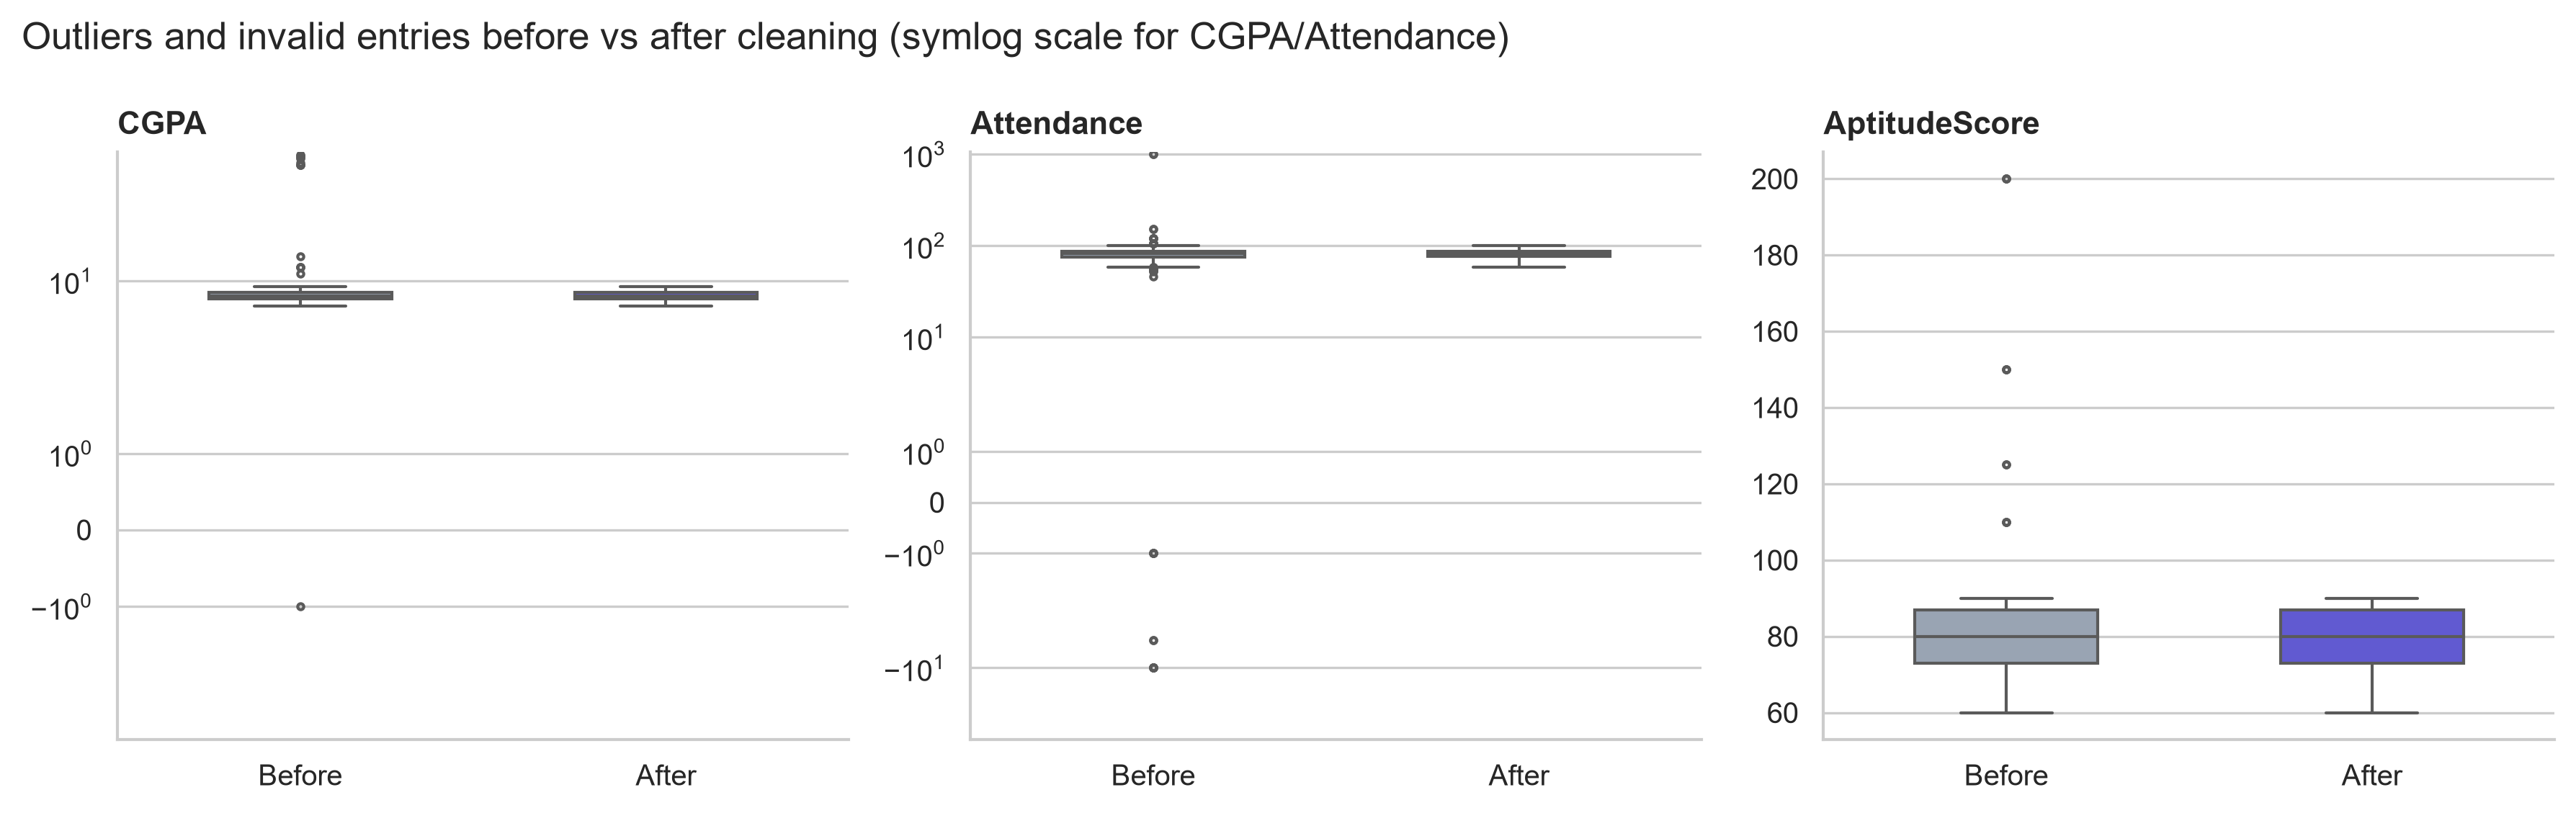

In [6]:
display(Image(filename=str(config.FIG_DIR / 'outliers_before_after.png'), width=800))

## 3. Models
Five models are tuned with `RandomizedSearchCV` (5-fold stratified CV, ROC-AUC) on the training set only.
The best one is chosen by **mean CV ROC-AUC**; the test set is used once at the end.

In [7]:
comp = pd.read_csv(config.MODEL_COMPARISON_CSV)
comp[["model", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "mcc",
      "cv_roc_auc_mean", "cv_roc_auc_std", "selected"]]

,model,accuracy,precision,recall,f1,roc_auc,pr_auc,mcc,cv_roc_auc_mean,cv_roc_auc_std,selected
0,XGBoost,0.797,0.777,0.726,0.750,0.869,0.834,0.581,0.865,0.005,True
1,Random Forest,0.791,0.772,0.712,0.741,0.865,0.826,0.567,0.864,0.005,False
2,SVM (RBF),0.802,0.789,0.722,0.754,0.868,0.838,0.591,0.862,0.005,False
3,Logistic Regression,0.799,0.770,0.745,0.757,0.866,0.838,0.587,0.861,0.005,False
4,KNN,0.798,0.776,0.731,0.753,0.864,0.821,0.584,0.860,0.005,False


In [8]:
print(metrics["training"]["statistical_test"]["interpretation"])

XGBoost vs Random Forest: mean CV ROC-AUC difference +0.0010. Paired t-test p = 0.328 (corrected p = 0.499); McNemar test on the test set p = 0.118. The difference is NOT statistically significant at the 5% level, so the two models perform practically the same on this data.


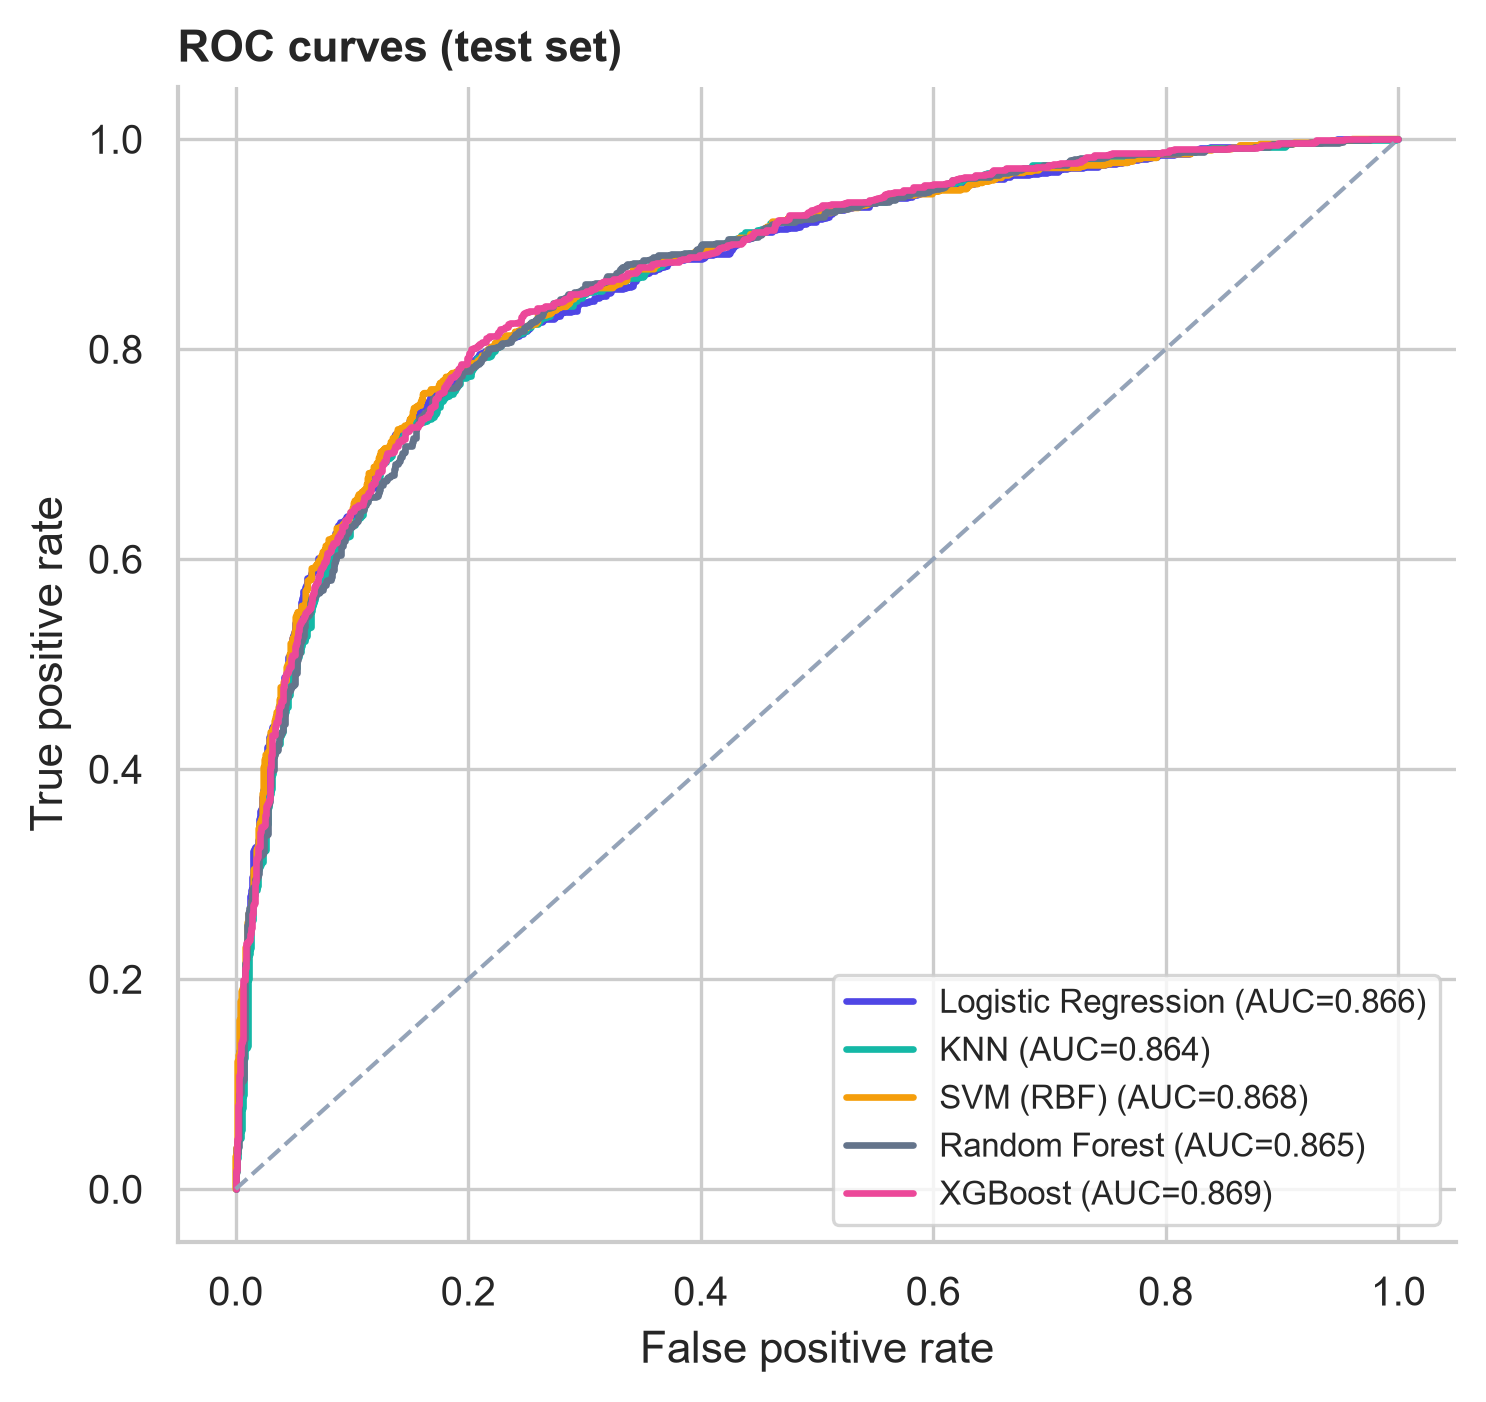

In [9]:
display(Image(filename=str(config.FIG_DIR / 'roc_curves.png'), width=500))

In [10]:
pd.read_csv(config.ABLATION_CSV)

,variant,n_features,cv_roc_auc_mean,cv_roc_auc_std,delta_vs_core
0,(a) 8 core features,8,0.865,0.005,0.000e+00
1,(b) core + engineered,11,0.864,0.004,-7.963e-04
2,(c) core + extra Kaggle columns,12,0.883,0.005,1.845e-02
3,(d) core - simulated columns,6,0.856,0.005,-8.122e-03


## 4. Influential features

In [11]:
fi = pd.read_csv(config.FEATURE_IMPORTANCE_CSV)
fi[["consensus_rank", "feature", "lr_coef_rank", "rf_impurity_rank", "xgb_gain_rank",
    "permutation_rank", "shap_rank", "mean_rank", "simulated"]]

,consensus_rank,feature,lr_coef_rank,rf_impurity_rank,xgb_gain_rank,permutation_rank,shap_rank,mean_rank,simulated
0,1,AptitudeScore,1,1,3,1,1,1.4,False
1,2,ProgrammingSkills,2,5,4,2,2,3.0,True
2,3,Certifications,5,3,2,4,3,3.4,False
3,4,CommunicationSkills,3,7,5,3,4,4.4,False
4,5,Projects,7,4,1,5,6,4.6,False
5,6,CGPA,6,2,6,6,5,5.0,False
6,7,Attendance,4,6,7,7,7,6.2,True
7,8,Internships,8,8,8,8,8,8.0,False


In [12]:
for s in metrics["insights"]:
    print("-", s)

- AptitudeScore is the most influential feature overall (consensus rank 1; ranked first by 4 of 5 methods).
- The three most influential features are AptitudeScore, ProgrammingSkills and Certifications.
- Average placement probability rises from 21% at AptitudeScore = 63 to 55% at AptitudeScore = 90; the steepest change is between 89 and 90.
- Average placement probability rises from 32% at ProgrammingSkills = 1 to 51% at ProgrammingSkills = 10; the steepest change is between 4 and 5.
- Average placement probability rises from 38% at Certifications = 0 to 46% at Certifications = 3; the steepest change is between 1 and 2.
- In the logistic regression model, a one-standard-deviation increase in AptitudeScore multiplies the odds of placement by 2.06.
- Internships has a negative coefficient in the logistic model: holding the other features fixed, higher values slightly reduce the odds of placement (odds ratio 0.94).
- The five importance methods agree moderately on the ranking: mean pairw

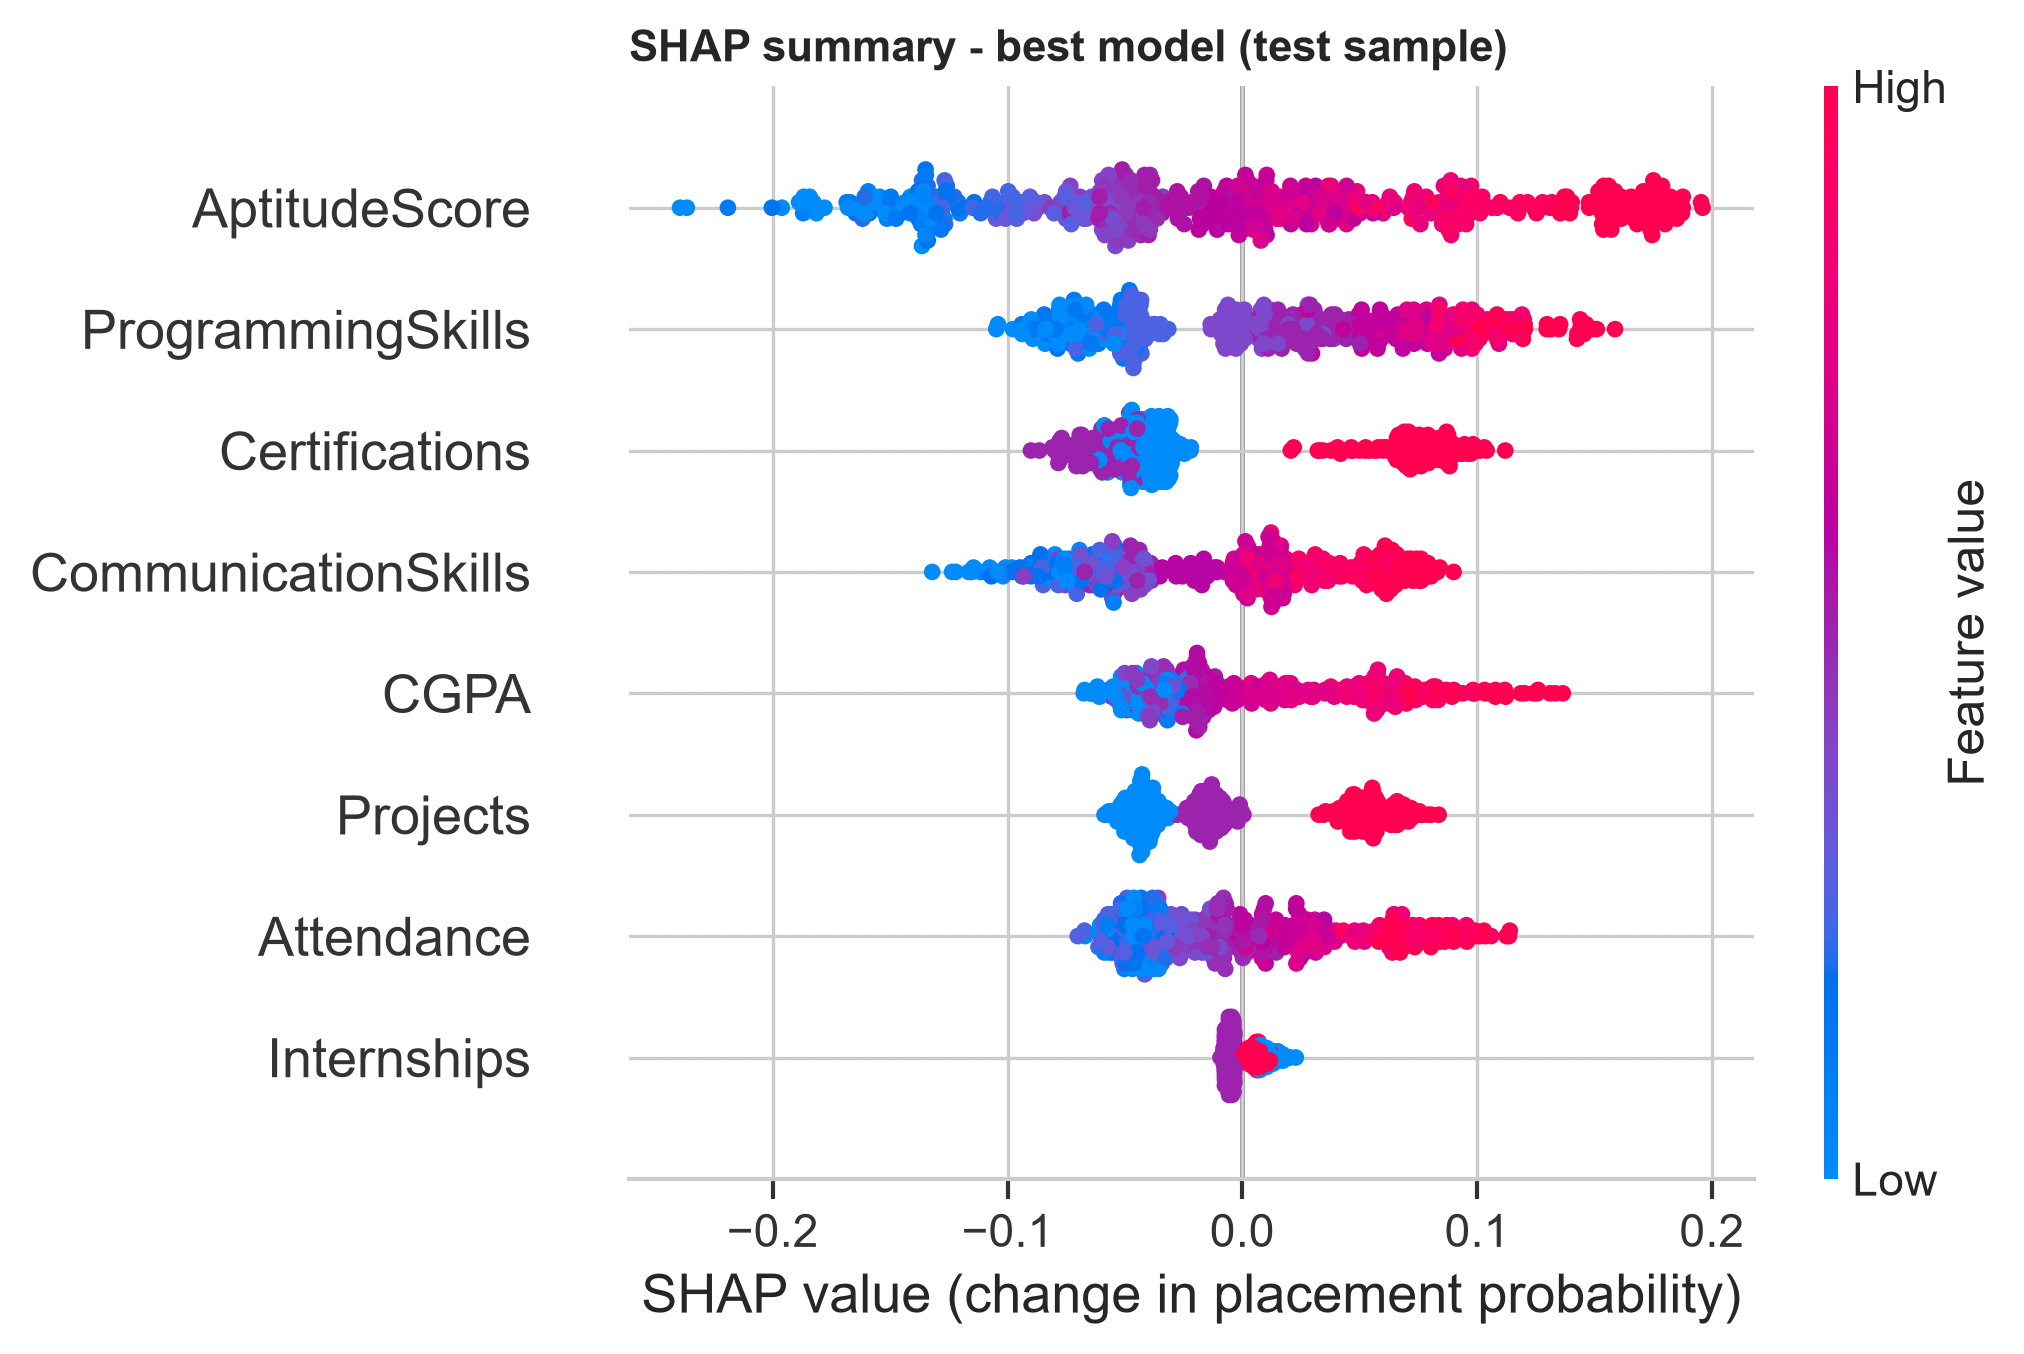

In [13]:
display(Image(filename=str(config.FIG_DIR / 'shap_summary_beeswarm.png'), width=650))

## 5. One student: prediction, explanation and what-if

In [14]:
from src.predict import load_model, predict_one, what_if

pipe, meta = load_model()
student = {"CGPA": 7.5, "ProgrammingSkills": 6, "Internships": 1, "Certifications": 1,
           "CommunicationSkills": 4.2, "AptitudeScore": 78, "Projects": 2, "Attendance": 82}
res = predict_one(student, pipe, meta)
print("Placement probability: %.1f%%  ->  %s" % (100 * res["proba"], "Placed" if res["label"] else "Not Placed"))
print("Average student (SHAP base value): %.1f%%" % (100 * res["base_value"]))
pd.Series(res["shap_values"]).mul(100).round(1).sort_values().to_frame("contribution (pts)")

C:\Users\naksh\OneDrive\Desktop\Campus-Placement-Predictor\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Placement probability: 18.7%  ->  Not Placed
Average student (SHAP base value): 41.2%


,contribution (pts)
Certifications,-6.4
CommunicationSkills,-4.9
AptitudeScore,-4.9
CGPA,-4.5
Attendance,-1.3
Projects,-1.2
Internships,-0.6
ProgrammingSkills,1.2


In [15]:
pd.DataFrame(what_if(student, pipe, meta))[["feature", "from", "to", "proba_before", "proba_after", "gain"]].head(5)

,feature,from,to,proba_before,proba_after,gain
0,Certifications,1.0,2.0,0.187,0.319,0.133
1,AptitudeScore,78.0,88.0,0.187,0.268,0.081
2,CommunicationSkills,4.2,4.7,0.187,0.263,0.077
3,CGPA,7.5,8.0,0.187,0.248,0.062
4,Attendance,82.0,87.0,0.187,0.240,0.053
